# Hestia A6 — AI Household Brain Dump

**Route A: Prompt Engineering · Person 1: Notebook + Research**

Hestia converts one household “brain dump” into separate, reviewable tasks. Each generated task must use the existing Django `Task` fields:

- `title`
- `task_type`
- `priority`
- `description`

This notebook defines the shared benchmark contract for all 15 models and evaluates Person 1's four lightweight models. It does **not** save generated tasks automatically; users must review and edit them before saving through Hestia.


In [1]:
# Model-weight download cell required by the assignment.
# Set to True only when preparing a machine for benchmarking; weights stay in
# the ignored Hugging Face cache and are never committed to Git.
DOWNLOAD_MODEL_WEIGHTS = False
MODELS_TO_DOWNLOAD = [
    "distilbert/distilgpt2",
    "HuggingFaceTB/SmolLM2-135M-Instruct",
    "HuggingFaceTB/SmolLM2-360M-Instruct",
    "Qwen/Qwen2.5-0.5B-Instruct",
    "Qwen/Qwen2-0.5B-Instruct",
    "HuggingFaceTB/SmolLM-360M-Instruct",
    "Qwen/Qwen3-0.6B",
    "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "Qwen/Qwen2.5-1.5B-Instruct",
    "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct",
    "meta-llama/Llama-3.2-3B-Instruct",
    "microsoft/Phi-3.5-mini-instruct",
    "mistralai/Mistral-7B-Instruct-v0.3",
    "Qwen/Qwen2.5-7B-Instruct",
]

if DOWNLOAD_MODEL_WEIGHTS:
    from huggingface_hub import snapshot_download

    for model_id in MODELS_TO_DOWNLOAD:
        try:
            snapshot_download(repo_id=model_id)
            print("Downloaded:", model_id)
        except Exception as exc:
            print(f"Could not download {model_id}: {type(exc).__name__}: {exc}")
else:
    print("Weight download is disabled. Set DOWNLOAD_MODEL_WEIGHTS=True to fetch all tested models.")


Weight download is disabled. Set DOWNLOAD_MODEL_WEIGHTS=True to fetch all tested models.


## Reproducibility rules

Every teammate must use:

1. The same two Brain Dump inputs.
2. The same system instruction and JSON schema.
3. The same zero-, one-, few-, and many-shot examples.
4. Deterministic generation (`do_sample=False`) with at most 220 new tokens.
5. The scoring rubric below.

Run locally in a Python 3.11 environment. Model weights remain in the Hugging Face cache and must **not** be committed.


In [2]:
# Run only if the environment is missing these packages.
# %pip install "torch>=2.2" "transformers>=4.46" pandas nbformat

import gc
import json
import platform
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

# Work whether Jupyter starts in the repository root or in llm-test/.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "llm-test" else CURRENT_DIR

print({
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu",
})

/Users/momo/Documents/12_HestiaaAI/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.14.6', 'torch': '2.14.1', 'transformers': '4.57.6', 'device': 'mps'}


## Five balanced model-size categories and tested 15-model roster

The assignment requires exactly three tested models in each of five parameter-size categories. The team selected its models before the final merge, so Person 1 sorted the **15 models actually benchmarked** by parameter count and divided the ordered list into five equal-count bands (three models per band). This quantile method preserves every real team result and makes comparisons balanced. The two 360M models tie across the first boundary; the notebook uses an alphabetical `model_id` tie-break solely for reproducible placement and does not claim that one is larger.


In [3]:
MODEL_ROSTER = [
    # Balanced parameter-size bands: exactly three tested models per category.
    {"category": "1 — Ultra-light (ranks 1–3)", "model_id": "distilbert/distilgpt2", "params_b": 0.082, "owner": "P1"},
    {"category": "1 — Ultra-light (ranks 1–3)", "model_id": "HuggingFaceTB/SmolLM2-135M-Instruct", "params_b": 0.135, "owner": "P1"},
    {"category": "1 — Ultra-light (ranks 1–3)", "model_id": "HuggingFaceTB/SmolLM-360M-Instruct", "params_b": 0.360, "owner": "P4"},

    {"category": "2 — Compact (ranks 4–6)", "model_id": "HuggingFaceTB/SmolLM2-360M-Instruct", "params_b": 0.360, "owner": "P1"},
    {"category": "2 — Compact (ranks 4–6)", "model_id": "Qwen/Qwen2-0.5B-Instruct", "params_b": 0.494, "owner": "P4"},
    {"category": "2 — Compact (ranks 4–6)", "model_id": "Qwen/Qwen2.5-0.5B-Instruct", "params_b": 0.494, "owner": "P1"},

    {"category": "3 — Small (ranks 7–9)", "model_id": "Qwen/Qwen3-0.6B", "params_b": 0.600, "owner": "P4"},
    {"category": "3 — Small (ranks 7–9)", "model_id": "TinyLlama/TinyLlama-1.1B-Chat-v1.0", "params_b": 1.10, "owner": "P2"},
    {"category": "3 — Small (ranks 7–9)", "model_id": "Qwen/Qwen2.5-1.5B-Instruct", "params_b": 1.54, "owner": "P2"},

    {"category": "4 — Medium (ranks 10–12)", "model_id": "HuggingFaceTB/SmolLM2-1.7B-Instruct", "params_b": 1.70, "owner": "P2"},
    {"category": "4 — Medium (ranks 10–12)", "model_id": "Qwen/Qwen2.5-3B-Instruct", "params_b": 3.09, "owner": "P2"},
    {"category": "4 — Medium (ranks 10–12)", "model_id": "meta-llama/Llama-3.2-3B-Instruct", "params_b": 3.21, "owner": "P3", "access": "gated"},

    {"category": "5 — Large (ranks 13–15)", "model_id": "microsoft/Phi-3.5-mini-instruct", "params_b": 3.82, "owner": "P3"},
    {"category": "5 — Large (ranks 13–15)", "model_id": "mistralai/Mistral-7B-Instruct-v0.3", "params_b": 7.25, "owner": "P3"},
    {"category": "5 — Large (ranks 13–15)", "model_id": "Qwen/Qwen2.5-7B-Instruct", "params_b": 7.62, "owner": "P3", "configuration": "NF4/float32 rerun"},
]

roster_df = pd.DataFrame(MODEL_ROSTER)
assert len(roster_df) == 15
assert roster_df["model_id"].nunique() == 15
assert roster_df.groupby("category")["model_id"].nunique().eq(3).all(), "Each size category must contain exactly three models"
roster_df


,category,model_id,params_b,owner,access,configuration
0,1 — Ultra-light (ranks 1–3),distilbert/distilgpt2,0.082,P1,NaN,NaN
1,1 — Ultra-light (ranks 1–3),HuggingFaceTB/SmolLM2-135M-Instruct,0.135,P1,NaN,NaN
2,1 — Ultra-light (ranks 1–3),HuggingFaceTB/SmolLM-360M-Instruct,0.360,P4,NaN,NaN
3,2 — Compact (ranks 4–6),HuggingFaceTB/SmolLM2-360M-Instruct,0.360,P1,NaN,NaN
4,2 — Compact (ranks 4–6),Qwen/Qwen2-0.5B-Instruct,0.494,P4,NaN,NaN
5,2 — Compact (ranks 4–6),Qwen/Qwen2.5-0.5B-Instruct,0.494,P1,NaN,NaN
6,3 — Small (ranks 7–9),Qwen/Qwen3-0.6B,0.600,P4,NaN,NaN
7,3 — Small (ranks 7–9),TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.100,P2,NaN,NaN
8,3 — Small (ranks 7–9),Qwen/Qwen2.5-1.5B-Instruct,1.540,P2,NaN,NaN
9,4 — Medium (ranks 10–12),HuggingFaceTB/SmolLM2-1.7B-Instruct,1.700,P2,NaN,NaN


## Shared Brain Dump contract

Allowed values match Hestia’s existing `Task.TaskType` and `Task.Priority` choices exactly. Models must return JSON only. The two fixed inputs test both direct extraction and judgment about urgency.


In [4]:
TASK_TYPES = {"CHORE", "APPOINTMENT", "DEADLINE", "ERRAND", "MAINTENANCE", "SHOPPING", "OTHER"}
PRIORITIES = {"LOW", "MEDIUM", "HIGH", "URGENT"}
REQUIRED_FIELDS = {"title", "task_type", "priority", "description"}

SYSTEM_INSTRUCTION = '''You are Hestia's household task extraction assistant.
Convert the user's message into separate household tasks.
Return JSON only in this exact shape:
{"tasks":[{"title":"...","task_type":"CHORE|APPOINTMENT|DEADLINE|ERRAND|MAINTENANCE|SHOPPING|OTHER","priority":"LOW|MEDIUM|HIGH|URGENT","description":"..."}]}
Do not invent concerns that the user did not mention. Use URGENT only for an immediate safety risk or a deadline within 24 hours. Keep titles and descriptions concise.'''

TEST_INPUTS = {
    "BD1": "Guests are coming tomorrow. The kitchen is messy, we need groceries, and the bathroom tap is leaking badly.",
    "BD2": "This week I need to book the dentist, replace the smoke detector batteries, return a library book by Friday, and wash the guest-room sheets.",
}

EXAMPLES = [
    {
        "input": "The trash is full and we are out of milk.",
        "output": {"tasks": [
            {"title": "Take out the trash", "task_type": "CHORE", "priority": "MEDIUM", "description": "Empty the full household trash bin."},
            {"title": "Buy milk", "task_type": "SHOPPING", "priority": "MEDIUM", "description": "Purchase milk for the household."},
        ]},
    },
    {
        "input": "The gas stove smells like gas, and the hallway light bulb needs replacing.",
        "output": {"tasks": [
            {"title": "Check gas leak", "task_type": "MAINTENANCE", "priority": "URGENT", "description": "Stop using the stove and arrange an immediate gas safety inspection."},
            {"title": "Replace hallway light bulb", "task_type": "MAINTENANCE", "priority": "LOW", "description": "Replace the burned-out hallway light bulb."},
        ]},
    },
    {
        "input": "The dog needs a vet appointment and the living room needs vacuuming.",
        "output": {"tasks": [
            {"title": "Book vet appointment", "task_type": "APPOINTMENT", "priority": "MEDIUM", "description": "Schedule a veterinary appointment for the dog."},
            {"title": "Vacuum living room", "task_type": "CHORE", "priority": "LOW", "description": "Vacuum the living-room floor."},
        ]},
    },
]

In [5]:
def build_user_prompt(text, shot_mode):
    shot_counts = {"zero": 0, "one": 1, "few": 2, "many": 3}
    if shot_mode not in shot_counts:
        raise ValueError(f"Unknown shot mode: {shot_mode}")
    examples = EXAMPLES[:shot_counts[shot_mode]]
    example_text = "\n\n".join(
        f"Example input: {item['input']}\nExample output: {json.dumps(item['output'])}"
        for item in examples
    )
    prefix = f"{example_text}\n\n" if example_text else ""
    return f"{prefix}Household message: {text}\nJSON output:"


def extract_json(text):
    # Extract the first complete JSON object without accepting Python literals.
    def reject_duplicate_keys(pairs):
        value = {}
        for key, item in pairs:
            if key in value:
                raise ValueError(f"Duplicate JSON key: {key}")
            value[key] = item
        return value

    decoder = json.JSONDecoder(object_pairs_hook=reject_duplicate_keys)
    for match in re.finditer(r"\{", text):
        try:
            value, _ = decoder.raw_decode(text[match.start():])
            return value
        except json.JSONDecodeError:
            continue
    raise ValueError("No valid JSON object found")


def validate_payload(payload):
    errors = []
    if not isinstance(payload, dict) or not isinstance(payload.get("tasks"), list):
        return ["Root must be an object containing a tasks list"]
    if not payload["tasks"]:
        errors.append("tasks must not be empty")
    for index, task in enumerate(payload["tasks"], start=1):
        if not isinstance(task, dict):
            errors.append(f"Task {index} is not an object")
            continue
        missing = REQUIRED_FIELDS - task.keys()
        if missing:
            errors.append(f"Task {index} missing: {sorted(missing)}")
        if task.get("task_type") not in TASK_TYPES:
            errors.append(f"Task {index} has invalid task_type")
        if task.get("priority") not in PRIORITIES:
            errors.append(f"Task {index} has invalid priority")
        if not str(task.get("title", "")).strip():
            errors.append(f"Task {index} has an empty title")
        if not str(task.get("description", "")).strip():
            errors.append(f"Task {index} has an empty description")
    return errors


# Small self-check for the shared parser and schema.
assert validate_payload(EXAMPLES[0]["output"]) == []
assert extract_json(f"result: {json.dumps(EXAMPLES[0]['output'])}") == EXAMPLES[0]["output"]

## Benchmark runner

Timing separates model loading from generation. `schema_valid` is automatic; content quality is scored manually after reading the complete output. Each model is unloaded before the next one to limit memory use.


In [6]:
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE in {"mps", "cuda"} else torch.float32
SHOT_MODES = ["zero", "one", "few", "many"]
PERSON_1_MODELS = [row["model_id"] for row in MODEL_ROSTER if row["owner"] == "P1"]


def format_for_model(tokenizer, user_prompt):
    messages = [
        {"role": "system", "content": SYSTEM_INSTRUCTION},
        {"role": "user", "content": user_prompt},
    ]
    if getattr(tokenizer, "chat_template", None):
        return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return f"Instruction:\n{SYSTEM_INSTRUCTION}\n\nUser:\n{user_prompt}\n\nAssistant:\n"


def benchmark_model(model_id):
    started = time.perf_counter()
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=DTYPE)
    model.to(DEVICE)
    model.eval()
    load_seconds = time.perf_counter() - started
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token_id = tokenizer.eos_token_id

    rows = []
    for input_id, brain_dump in TEST_INPUTS.items():
        for shot_mode in SHOT_MODES:
            prompt = format_for_model(tokenizer, build_user_prompt(brain_dump, shot_mode))
            encoded = tokenizer(prompt, return_tensors="pt").to(DEVICE)
            generation_started = time.perf_counter()
            with torch.inference_mode():
                generated = model.generate(
                    **encoded,
                    max_new_tokens=220,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id,
                )
            generation_seconds = time.perf_counter() - generation_started
            new_tokens = generated[0, encoded["input_ids"].shape[1]:]
            raw_output = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
            try:
                payload = extract_json(raw_output)
                validation_errors = validate_payload(payload)
            except (ValueError, json.JSONDecodeError) as exc:
                payload = None
                validation_errors = [str(exc)]
            rows.append({
                "model_id": model_id,
                "input_id": input_id,
                "shot_mode": shot_mode,
                "load_seconds": round(load_seconds, 3),
                "generation_seconds": round(generation_seconds, 3),
                "output_tokens": int(new_tokens.shape[-1]),
                "schema_valid": not validation_errors,
                "validation_errors": " | ".join(validation_errors),
                "raw_output": raw_output,
                "quality_score_0_to_10": None,
                "review_notes": "",
            })

    del model, tokenizer
    gc.collect()
    if DEVICE == "mps":
        torch.mps.empty_cache()
    elif DEVICE == "cuda":
        torch.cuda.empty_cache()
    return rows


print("Device:", DEVICE)
print("Person 1 models:", PERSON_1_MODELS)

Device: mps
Person 1 models: ['distilbert/distilgpt2', 'HuggingFaceTB/SmolLM2-135M-Instruct', 'HuggingFaceTB/SmolLM2-360M-Instruct', 'Qwen/Qwen2.5-0.5B-Instruct']


In [7]:
# Set this to True only when deliberately rerunning P1 inference.
# The final team notebook defaults to the committed evidence so execution does not
# download model weights or overwrite reviewed results.
RUN_PERSON1_INFERENCE = False
RESULTS_DIR = PROJECT_ROOT / "a6_results"
PERSON1_RESULTS = RESULTS_DIR / "person1_benchmark_results.csv"

if RUN_PERSON1_INFERENCE:
    all_rows = []
    for model_id in PERSON_1_MODELS:
        print(f"Benchmarking {model_id}...")
        try:
            all_rows.extend(benchmark_model(model_id))
        except Exception as exc:
            all_rows.append({
                "model_id": model_id,
                "input_id": "MODEL_LOAD",
                "shot_mode": "n/a",
                "load_seconds": None,
                "generation_seconds": None,
                "output_tokens": None,
                "schema_valid": False,
                "validation_errors": f"{type(exc).__name__}: {exc}",
                "raw_output": "",
                "quality_score_0_to_10": None,
                "review_notes": "Model could not be benchmarked; retain the error as evidence.",
            })
    results_df = pd.DataFrame(all_rows)
else:
    results_df = pd.read_csv(PERSON1_RESULTS)
    print(f"Loaded {len(results_df)} reviewed P1 runs from {PERSON1_RESULTS}")

results_df.head()


Loaded 32 reviewed P1 runs from /Users/momo/Documents/12_HestiaaAI/a6_results/person1_benchmark_results.csv


,model_id,input_id,shot_mode,load_seconds,generation_seconds,output_tokens,schema_valid,validation_errors,raw_output,quality_score_0_to_10,review_notes
0,distilbert/distilgpt2,BD1,zero,0.942,1.810,220,False,No valid JSON object found,Household message: Guests are coming tomorrow....,0,Repeated the prompt; no tasks or JSON.
1,distilbert/distilgpt2,BD1,one,0.942,1.510,220,True,NaN,"Example input: ""Buy milk"", ""task_type"": ""SHOPP...",1,Copied an example instead of extracting the us...
2,distilbert/distilgpt2,BD1,few,0.942,1.619,220,True,NaN,"Example input: The kitchen is messy, we need g...",1,Repeated examples; the parsed task is unrelate...
3,distilbert/distilgpt2,BD1,many,0.942,1.777,220,True,NaN,Example input: The kitchen is clean and we are...,1,Copied the vet example and missed all requeste...
4,distilbert/distilgpt2,BD2,zero,0.942,1.381,220,False,No valid JSON object found,Household message: This week I need to book th...,0,Repeated the prompt; no tasks or JSON.


## Human evaluation rubric (10 points)

Score every successful response using the same rubric:

| Criterion | Points | What to check |
|---|---:|---|
| Task extraction | 0–3 | All stated concerns become separate tasks; no invented tasks |
| Task type | 0–2 | Existing Hestia task types are appropriate |
| Priority | 0–2 | Urgency and deadlines are interpreted reasonably |
| Clarity | 0–2 | Titles and descriptions are concise and actionable |
| Format reliability | 0–1 | Valid JSON with the exact required fields |

Enter the total and a short justification in `quality_score_0_to_10` and `review_notes`. Do not invent scores for outputs that were not reviewed.


In [8]:
# Person 1 reviewed every raw output against the rubric above.
# Keys are (model_id, input_id, shot_mode); values are (score, concise justification).
MANUAL_REVIEWS = {
    ("distilbert/distilgpt2", "BD1", "zero"): (0, "Repeated the prompt; no tasks or JSON."),
    ("distilbert/distilgpt2", "BD1", "one"): (1, "Copied an example instead of extracting the user's concerns."),
    ("distilbert/distilgpt2", "BD1", "few"): (1, "Repeated examples; the parsed task is unrelated to the input."),
    ("distilbert/distilgpt2", "BD1", "many"): (1, "Copied the vet example and missed all requested tasks."),
    ("distilbert/distilgpt2", "BD2", "zero"): (0, "Repeated the prompt; no tasks or JSON."),
    ("distilbert/distilgpt2", "BD2", "one"): (1, "Copied the milk example and missed the four concerns."),
    ("distilbert/distilgpt2", "BD2", "few"): (1, "Repeated examples rather than producing input-specific tasks."),
    ("distilbert/distilgpt2", "BD2", "many"): (1, "Copied the vet example and missed the four concerns."),

    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD1", "zero"): (0, "Returned the schema placeholder, not extracted tasks."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD1", "one"): (0, "Repeated one example until the output was truncated."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD1", "few"): (0, "Repeated example fields and produced incomplete JSON."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD1", "many"): (1, "Mentioned guests but missed the three actionable concerns."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD2", "zero"): (0, "Returned the schema placeholder, not extracted tasks."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD2", "one"): (2, "Recognized some concerns but collapsed them into duplicate JSON keys."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD2", "few"): (2, "Mentioned the concerns but collapsed them into malformed JSON."),
    ("HuggingFaceTB/SmolLM2-135M-Instruct", "BD2", "many"): (3, "Started separate relevant tasks but repeated keys and was truncated."),

    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD1", "zero"): (7, "Extracted all three concerns clearly; task_type values were outside Hestia's choices."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD1", "one"): (5, "Found groceries and the tap but replaced kitchen cleaning with the example trash task."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD1", "few"): (7, "Extracted all concerns; grocery type and priorities need correction."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD1", "many"): (6, "Extracted all concerns but overused MAINTENANCE and weak priorities."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD2", "zero"): (3, "Recognized several concerns but used placeholder enums and incomplete JSON."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD2", "one"): (7, "Extracted all four tasks clearly; most task types were incorrect."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD2", "few"): (7, "Extracted all four tasks; types and deadline priority were weak."),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", "BD2", "many"): (8, "Extracted four clear tasks; two classifications still need editing."),

    ("Qwen/Qwen2.5-0.5B-Instruct", "BD1", "zero"): (9, "Extracted all three concerns with useful priorities; groceries should be SHOPPING."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD1", "one"): (6, "Handled groceries and the leak but invented dinner and switched descriptions to Chinese."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD1", "few"): (5, "Invented dinner and mixed the grocery and tap descriptions."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD1", "many"): (5, "Missed kitchen cleaning and mixed grocery and maintenance details."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD2", "zero"): (7, "Extracted all four tasks; several types and the sheet priority were incorrect."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD2", "one"): (6, "Extracted four tasks but invented details and ignored allowed task types."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD2", "few"): (7, "Extracted four clear tasks; most types need correction."),
    ("Qwen/Qwen2.5-0.5B-Instruct", "BD2", "many"): (8, "Produced four usable tasks; invented a dentist/date detail and understated Friday urgency."),
}

for index, row in results_df.iterrows():
    key = (row["model_id"], row["input_id"], row["shot_mode"])
    if key in MANUAL_REVIEWS:
        results_df.at[index, "quality_score_0_to_10"] = MANUAL_REVIEWS[key][0]
        results_df.at[index, "review_notes"] = MANUAL_REVIEWS[key][1]

assert results_df["quality_score_0_to_10"].notna().all(), "Every successful P1 run must be reviewed"
results_df.groupby("model_id").agg(
    mean_quality=("quality_score_0_to_10", "mean"),
    json_success_rate=("schema_valid", "mean"),
    mean_generation_seconds=("generation_seconds", "mean"),
).round(3)

,mean_quality,json_success_rate,mean_generation_seconds
model_id,,,
HuggingFaceTB/SmolLM2-135M-Instruct,1.000,0.000,2.465
HuggingFaceTB/SmolLM2-360M-Instruct,6.250,0.750,3.148
Qwen/Qwen2.5-0.5B-Instruct,6.625,0.875,2.876
distilbert/distilgpt2,0.750,0.750,1.618


In [9]:
# Example review workflow: filter one model/input, read raw_output, then assign honest scores.
results_df[["model_id", "input_id", "shot_mode", "schema_valid", "quality_score_0_to_10", "raw_output"]]

,model_id,input_id,shot_mode,schema_valid,quality_score_0_to_10,raw_output
0,distilbert/distilgpt2,BD1,zero,False,0,Household message: Guests are coming tomorrow....
1,distilbert/distilgpt2,BD1,one,True,1,"Example input: ""Buy milk"", ""task_type"": ""SHOPP..."
2,distilbert/distilgpt2,BD1,few,True,1,"Example input: The kitchen is messy, we need g..."
3,distilbert/distilgpt2,BD1,many,True,1,Example input: The kitchen is clean and we are...
4,distilbert/distilgpt2,BD2,zero,False,0,Household message: This week I need to book th...
5,distilbert/distilgpt2,BD2,one,True,1,Example input: The trash is full and we are ou...
6,distilbert/distilgpt2,BD2,few,True,1,Example input: The trash is full and we are ou...
7,distilbert/distilgpt2,BD2,many,True,1,Example input: The dog needs a vet appointment...
8,HuggingFaceTB/SmolLM2-135M-Instruct,BD1,zero,False,0,"{""tasks"":[{""title"":""..."",""task_type"":""CHORE|AP..."
9,HuggingFaceTB/SmolLM2-135M-Instruct,BD1,one,False,0,"{""tasks"":[{""title"":""Take out the trash"", ""task..."


In [10]:
# Save only after a deliberate P1 inference rerun. Normal final-notebook execution
# preserves the reviewed CSV already committed by Person 1.
RESULTS_DIR.mkdir(exist_ok=True)
output_path = RESULTS_DIR / "person1_benchmark_results.csv"
if RUN_PERSON1_INFERENCE:
    results_df.to_csv(output_path, index=False)
    print("Saved rerun:", output_path)
    print("Generated at:", datetime.now(timezone.utc).isoformat())
else:
    print("Preserved reviewed evidence:", output_path)


Preserved reviewed evidence: /Users/momo/Documents/12_HestiaaAI/a6_results/person1_benchmark_results.csv


## Final team merge

The four canonical CSV files use the shared 11-column contract. The merge below validates file count, schema, duplicate keys, run count, distinct models and roster coverage before analysis.


In [11]:
RESULT_COLUMNS = [
    "model_id", "input_id", "shot_mode", "load_seconds", "generation_seconds",
    "output_tokens", "schema_valid", "validation_errors", "raw_output",
    "quality_score_0_to_10", "review_notes",
]

result_files = [RESULTS_DIR / f"person{person}_benchmark_results.csv" for person in range(1, 5)]
missing_files = [str(path) for path in result_files if not path.exists()]
assert not missing_files, f"Missing team result files: {missing_files}"

frames = []
for source_path in result_files:
    frame = pd.read_csv(source_path)
    missing_columns = set(RESULT_COLUMNS) - set(frame.columns)
    assert not missing_columns, f"{source_path} missing columns: {sorted(missing_columns)}"
    frame = frame[RESULT_COLUMNS].copy()
    frame["source_file"] = source_path.name
    frames.append(frame)

combined_df = pd.concat(frames, ignore_index=True)
combined_df["schema_valid"] = combined_df["schema_valid"].map(
    lambda value: value if isinstance(value, bool) else str(value).strip().lower() == "true"
)
combined_df["quality_score_0_to_10"] = pd.to_numeric(combined_df["quality_score_0_to_10"], errors="coerce")

key_columns = ["model_id", "input_id", "shot_mode"]
assert not combined_df.duplicated(key_columns).any(), "Duplicate model/input/shot rows found"
assert len(combined_df) == 120, f"Expected 120 runs, found {len(combined_df)}"
assert combined_df["model_id"].nunique() == 15, "Expected 15 distinct tested models"
assert combined_df.groupby("model_id").size().eq(8).all(), "Every model must have 8 runs"

analysis_df = combined_df.merge(
    roster_df[["model_id", "category", "params_b", "owner"]],
    on="model_id",
    how="left",
    validate="many_to_one",
)
assert analysis_df[["category", "params_b", "owner"]].notna().all().all(), "A tested model is missing from the roster"

coverage = (
    roster_df.groupby("category", observed=False)
    .agg(models=("model_id", "nunique"), owners=("owner", lambda values: ", ".join(sorted(set(values)))))
    .reset_index()
)
print(f"Validated {len(combined_df)} runs from {len(result_files)} files and {combined_df['model_id'].nunique()} models")
display(coverage)
combined_df.head()


Validated 120 runs from 4 files and 15 models


,category,models,owners
0,1 — Ultra-light (ranks 1–3),3,"P1, P4"
1,2 — Compact (ranks 4–6),3,"P1, P4"
2,3 — Small (ranks 7–9),3,"P2, P4"
3,4 — Medium (ranks 10–12),3,"P2, P3"
4,5 — Large (ranks 13–15),3,P3


,model_id,input_id,shot_mode,load_seconds,generation_seconds,output_tokens,schema_valid,validation_errors,raw_output,quality_score_0_to_10,review_notes,source_file
0,distilbert/distilgpt2,BD1,zero,0.942,1.810,220,False,No valid JSON object found,Household message: Guests are coming tomorrow....,0.0,Repeated the prompt; no tasks or JSON.,person1_benchmark_results.csv
1,distilbert/distilgpt2,BD1,one,0.942,1.510,220,True,NaN,"Example input: ""Buy milk"", ""task_type"": ""SHOPP...",1.0,Copied an example instead of extracting the us...,person1_benchmark_results.csv
2,distilbert/distilgpt2,BD1,few,0.942,1.619,220,True,NaN,"Example input: The kitchen is messy, we need g...",1.0,Repeated examples; the parsed task is unrelate...,person1_benchmark_results.csv
3,distilbert/distilgpt2,BD1,many,0.942,1.777,220,True,NaN,Example input: The kitchen is clean and we are...,1.0,Copied the vet example and missed all requeste...,person1_benchmark_results.csv
4,distilbert/distilgpt2,BD2,zero,0.942,1.381,220,False,No valid JSON object found,Household message: This week I need to book th...,0.0,Repeated the prompt; no tasks or JSON.,person1_benchmark_results.csv


## Part 3 Q1 — Size vs Quality (final team analysis)

Across the **120 reviewed runs from 15 distinct models**, the five balanced size bands contain exactly three models and 24 runs each. Mean reviewed quality generally increased with model size: **0.583/10** for ultra-light, **6.000/10** for compact, **5.333/10** for small, **6.667/10** for medium and **8.646/10** for large. The slight compact-to-small decrease shows that parameter count alone does not guarantee better extraction.

The strongest tested model was **Qwen2.5-7B-Instruct** at **9.375/10** with 8/8 schema-valid outputs, followed by **Mistral-7B-Instruct-v0.3** at **8.562/10**. At the same nominal 360M size, SmolLM-360M scored **0.000**, while the newer instruction-tuned SmolLM2-360M scored **6.250**. DistilGPT2 produced parseable JSON in 6/8 runs but averaged only **0.750** because it often copied examples instead of extracting the user's concerns. Llama-3.2-3B averaged **7.750** while only 1/8 outputs passed the strict schema. Architecture, instruction tuning, configuration and format reliability therefore matter alongside parameter count.

Prompt examples helped on average but were not universally beneficial. Team-wide mean quality increased from **4.617** zero-shot to **5.483** one-shot, **5.817** few-shot and **5.867** many-shot. Some individual models became distracted by demonstrations, so the application must still validate and let users edit every result.

The practical recommendation from the tested evidence is **Qwen2.5-7B-Instruct** when quality is the priority and the hardware can run it. **SmolLM2-1.7B-Instruct** is a lighter compromise at **7.000/10** with 8/8 schema-valid outputs. Hestia should keep deterministic generation, strict JSON validation and human review regardless of model size.

### Category method and limitation

These are balanced **rank-based parameter-size bands**, created from the 15 models the team actually tested. This supports the required three-model comparison in each of five categories without inventing results. The bands are specific to this benchmark roster and should not be treated as universal industry size definitions. The tied 360M models were separated with an alphabetical model-ID tie-break. The largest tested model is 7.62B, so the evidence does not support conclusions about models above that size.


,category,model_id,params_b,mean_quality,valid_json,total_runs,mean_generation_seconds,json_success_rate
2,1 — Ultra-light (ranks 1–3),distilbert/distilgpt2,0.082,0.750,6,8,1.618,0.750
1,1 — Ultra-light (ranks 1–3),HuggingFaceTB/SmolLM2-135M-Instruct,0.135,1.000,0,8,2.465,0.000
0,1 — Ultra-light (ranks 1–3),HuggingFaceTB/SmolLM-360M-Instruct,0.360,0.000,0,8,26.817,0.000
3,2 — Compact (ranks 4–6),HuggingFaceTB/SmolLM2-360M-Instruct,0.360,6.250,6,8,3.148,0.750
4,2 — Compact (ranks 4–6),Qwen/Qwen2-0.5B-Instruct,0.494,5.125,1,8,18.891,0.125
5,2 — Compact (ranks 4–6),Qwen/Qwen2.5-0.5B-Instruct,0.494,6.625,7,8,2.876,0.875
7,3 — Small (ranks 7–9),Qwen/Qwen3-0.6B,0.600,6.375,7,8,23.354,0.875
8,3 — Small (ranks 7–9),TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.100,4.375,7,8,8.628,0.875
6,3 — Small (ranks 7–9),Qwen/Qwen2.5-1.5B-Instruct,1.540,5.250,6,8,11.024,0.750
9,4 — Medium (ranks 10–12),HuggingFaceTB/SmolLM2-1.7B-Instruct,1.700,7.000,8,8,10.354,1.000


,category,models,runs,mean_quality,json_success_rate,mean_generation_seconds
0,1 — Ultra-light (ranks 1–3),3,24,0.583,0.250,10.300
1,2 — Compact (ranks 4–6),3,24,6.000,0.583,8.305
2,3 — Small (ranks 7–9),3,24,5.333,0.833,14.335
3,4 — Medium (ranks 10–12),3,24,6.667,0.625,13.867
4,5 — Large (ranks 13–15),3,24,8.646,0.833,10.595


,shot_mode,runs,mean_quality,json_success_rate
0,zero,30,4.617,0.400
1,one,30,5.483,0.667
2,few,30,5.817,0.700
3,many,30,5.867,0.733


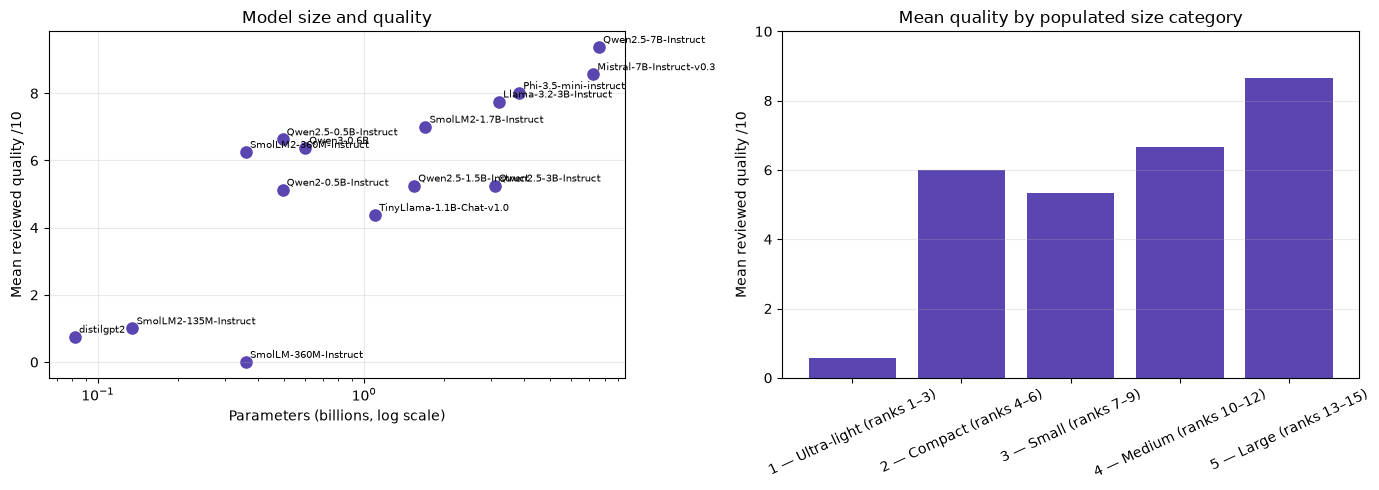

In [12]:
reviewed = analysis_df.dropna(subset=["quality_score_0_to_10"]).copy()
assert len(reviewed) == 120, "All selected runs must have a reviewed quality score"

model_summary = (
    reviewed.groupby(["category", "model_id", "params_b"], dropna=False, observed=False)
    .agg(
        mean_quality=("quality_score_0_to_10", "mean"),
        valid_json=("schema_valid", "sum"),
        total_runs=("schema_valid", "size"),
        mean_generation_seconds=("generation_seconds", "mean"),
    )
    .reset_index()
    .sort_values(["params_b", "model_id"])
)
model_summary["json_success_rate"] = model_summary["valid_json"] / model_summary["total_runs"]

category_summary = (
    reviewed.groupby("category", observed=False)
    .agg(
        models=("model_id", "nunique"),
        runs=("model_id", "size"),
        mean_quality=("quality_score_0_to_10", "mean"),
        json_success_rate=("schema_valid", "mean"),
        mean_generation_seconds=("generation_seconds", "mean"),
    )
    .reset_index()
)

prompt_summary = (
    reviewed.groupby("shot_mode", observed=False)
    .agg(runs=("model_id", "size"), mean_quality=("quality_score_0_to_10", "mean"), json_success_rate=("schema_valid", "mean"))
    .reindex(["zero", "one", "few", "many"])
    .reset_index()
)

display(model_summary.round(3))
display(category_summary.round(3))
display(prompt_summary.round(3))

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(model_summary["params_b"], model_summary["mean_quality"], color="#5b45b0", s=65)
for _, row in model_summary.iterrows():
    axes[0].annotate(row["model_id"].split("/")[-1], (row["params_b"], row["mean_quality"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].set_xscale("log")
axes[0].set_xlabel("Parameters (billions, log scale)")
axes[0].set_ylabel("Mean reviewed quality /10")
axes[0].set_title("Model size and quality")
axes[0].grid(alpha=0.25)

axes[1].bar(category_summary["category"], category_summary["mean_quality"], color="#5b45b0")
axes[1].set_ylim(0, 10)
axes[1].set_ylabel("Mean reviewed quality /10")
axes[1].set_title("Mean quality by populated size category")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
